In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import eigsh

# Time-independent Schrödinger equation for the harmonic oscillator

This notebook is based on the discussion of the harmonic oscillator in Chapter 2 of David J. Griffiths and Darrell F. Schroeter, *Introduction to Quantum Mechanics*, third edition, Cambridge University Press, 2018.

The time-independent Schrödinger equation for a particle in a one-dimensional harmonic potential is
$$
    - \frac{\hbar^2}{2m} \frac{d^2 \psi}{dx^2} + \frac{1}{2} m \omega^2 x^2 \psi = E \psi
$$
Introducing dimensionless variables gives
$$
    \left(-\frac{d^2}{d\xi^2} + \xi^2\right) \psi(\xi) = K \psi(\xi),
$$
where $\xi = \sqrt{m\omega/\hbar}\,x$ and $K = 2E/(\hbar\omega)$. The exact eigenvalues are $K_n = 2n + 1$, corresponding to $E_n = (n + \tfrac{1}{2})\hbar\omega$.

After discretization, $-d^2/d\xi^2 + \xi^2$ becomes a matrix. The sampled wavefunctions are its eigenvectors and the corresponding values of $K$ are its eigenvalues.

Discretize $\xi \in [\xi_{\min}, \xi_{\max}]$ on an evenly spaced grid, $\xi_i = \xi_{\min} + i\Delta\xi$, and write $\psi_i = \psi(\xi_i)$. At an interior grid point, the centered second-order approximation is

$$
    \frac{d^2 \psi}{d \xi^2}(\xi_i) \approx \frac{\psi_{i - 1} - 2\psi_i + \psi_{i + 1}}{\Delta\xi^2}.
$$
Therefore the interior rows of the dimensionless Hamiltonian have the form
$$
    (0, \ldots, 0, -1/\Delta\xi^2, 2/\Delta\xi^2 + \xi_i^2, -1/\Delta\xi^2, 0, \ldots, 0).
$$
The physical wavefunctions decay as $|\xi| \to \infty$. On the finite interval we approximate this with homogeneous Dirichlet boundary conditions, $\psi(\xi_{\min}) = \psi(\xi_{\max}) = 0$, and solve only for the interior grid values. This gives a real symmetric tridiagonal matrix.

For example, with unit spacing the matrix representing $-d^2/d\xi^2$ on four interior points is:

In [2]:
nr_demo_points = 4
minus_second_derivative = sp.diags(
    (
        -np.ones(nr_demo_points - 1),
        2 * np.ones(nr_demo_points),
        -np.ones(nr_demo_points - 1),
    ),
    offsets=(-1, 0, 1),
    format="csr",
)
minus_second_derivative.toarray()

array([[ 2., -1.,  0.,  0.],
       [-1.,  2., -1.,  0.],
       [ 0., -1.,  2., -1.],
       [ 0.,  0., -1.,  2.]])

First define the full grid and its spacing $\Delta\xi$. The endpoints are boundary points; the eigenvalue problem is solved at the interior points only.

In [3]:
ξ_min, ξ_max = -8.0, 8.0
nr_points = 201
ξ_full = np.linspace(ξ_min, ξ_max, nr_points)
Δξ = ξ_full[1] - ξ_full[0]
ξ = ξ_full[1:-1]

The Hamiltonian is approximated with the centered second-order stencil. The potential values $\xi_i^2$ are added to the main diagonal.

In [4]:
main_diagonal = 2 / Δξ**2 + ξ**2
off_diagonal = -np.ones(ξ.size - 1) / Δξ**2
hamiltonian = sp.diags(
    (off_diagonal, main_diagonal, off_diagonal),
    offsets=(-1, 0, 1),
    format="csr",
)

We only need the four lowest-energy states. Because the matrix is real and symmetric, `eigsh` is the appropriate sparse eigensolver; `which="SA"` requests the smallest algebraic eigenvalues. The returned eigenvectors are normalized with respect to the discrete approximation of $\int |\psi|^2\,d\xi$.

In [5]:
eigen_values, eigen_vectors = eigsh(hamiltonian, k=4, which="SA")
order = np.argsort(eigen_values)
eigen_values = eigen_values[order]
eigen_vectors = eigen_vectors[:, order]
eigen_vectors /= np.sqrt(
    np.sum(np.abs(eigen_vectors) ** 2, axis=0) * Δξ
)

The computed eigenvalues should approach $K_n = 2n + 1$. The remaining error comes from the finite grid spacing and the truncation of the infinite domain. The columns below contain the numerical value, the exact value, and their difference.

In [6]:
expected_eigen_values = 2 * np.arange(eigen_values.size) + 1
np.testing.assert_allclose(
    eigen_values, expected_eigen_values, rtol=0.0, atol=2e-2
)
np.column_stack(
    (
        eigen_values,
        expected_eigen_values,
        eigen_values - expected_eigen_values,
    )
)

array([[ 9.99599840e-01,  1.00000000e+00, -4.00160192e-04],
       [ 2.99799856e+00,  3.00000000e+00, -2.00144289e-03],
       [ 4.99479438e+00,  5.00000000e+00, -5.20561600e-03],
       [ 6.98998538e+00,  7.00000000e+00, -1.00146150e-02]])

In [7]:
eigen_vectors.shape, np.sum(np.abs(eigen_vectors) ** 2, axis=0) * Δξ

((199, 4), array([1., 1., 1., 1.]))

Each column of `eigen_vectors` contains one normalized wavefunction sampled at the interior grid points. For plotting, zeros are restored at the two boundary points. The eigenfunctions are scaled and shifted vertically by their eigenvalues; this is only a visualization convention.

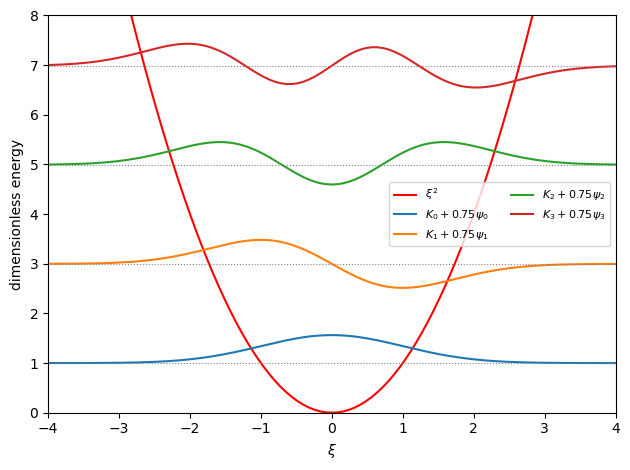

In [8]:
wavefunctions = np.zeros((nr_points, eigen_vectors.shape[1]))
wavefunctions[1:-1, :] = eigen_vectors
for state in range(wavefunctions.shape[1]):
    largest_component = np.argmax(np.abs(wavefunctions[:, state]))
    if wavefunctions[largest_component, state] < 0:
        wavefunctions[:, state] *= -1

fig, ax = plt.subplots()
ax.plot(ξ_full, ξ_full**2, color="red", label=r"$\xi^2$")
for state, (eigen_value, wavefunction) in enumerate(
    zip(eigen_values, wavefunctions.T, strict=True)
):
    ax.plot(
        ξ_full,
        eigen_value + 0.75 * wavefunction,
        label=rf"$K_{state} + 0.75\psi_{state}$",
    )
    ax.axhline(eigen_value, color="gray", linestyle=":", linewidth=0.8)
ax.set(
    xlim=(-4.0, 4.0),
    ylim=(0.0, 8.0),
    xlabel=r"$\xi$",
    ylabel="dimensionless energy",
)
ax.legend(ncols=2, fontsize=8)
fig.tight_layout()

The numerical eigenvalues agree with the exact spectrum to the expected discretization accuracy. The eigenfunctions also have the expected parity and number of nodes: the state $n$ has $n$ nodes. Refining the grid reduces the second-order finite-difference error, provided the interval remains wide enough that the wavefunctions are negligible at its endpoints.

## Optional extension: constructing the operator with `findiff`

The explicit SciPy construction above makes the stencil and boundary treatment visible. The [`findiff`](https://maroba.github.io/findiff/) package provides a higher-level representation of the same differential operator. Here we use it to reconstruct the Hamiltonian and verify that it produces the same eigenproblem.

`Diff.matrix` uses one-sided stencils in the boundary rows by default. Those rows are useful when differentiating sampled data at its endpoints, but they should not be included as equations in this self-adjoint eigenvalue problem. We therefore impose homogeneous Dirichlet conditions explicitly; `findiff` then eliminates the boundary degrees of freedom before calling the symmetric eigensolver.

In [9]:
from findiff import BoundaryConditions, Diff, Identity

findiff_second_derivative = Diff(0, Δξ) ** 2
findiff_hamiltonian = (
    -1 * findiff_second_derivative + ξ_full**2 * Identity()
)
findiff_boundary_conditions = BoundaryConditions(ξ_full.shape)
findiff_boundary_conditions[0] = 0
findiff_boundary_conditions[-1] = 0

Before solving, compare the interior matrix produced by `findiff` with the matrix constructed explicitly above. Removing the first and last rows and columns corresponds to substituting the known zero boundary values.

In [10]:
findiff_interior_matrix = findiff_hamiltonian.matrix(
    ξ_full.shape
)[1:-1, 1:-1]
matrix_difference = findiff_interior_matrix - hamiltonian
assert matrix_difference.nnz == 0
findiff_interior_matrix.shape, matrix_difference.nnz

((199, 199), 0)

Now solve with `findiff`'s boundary-aware `eigsh` method. Its eigenvectors include the two boundary points and use Euclidean normalization, so we rescale them using the same discrete integral as before. The displayed columns are the `findiff` eigenvalues, the explicit SciPy eigenvalues, and their differences.

In [11]:
findiff_eigen_values, findiff_wavefunctions = findiff_hamiltonian.eigsh(
    ξ_full.shape,
    k=4,
    which="SA",
    bc=findiff_boundary_conditions,
)
findiff_order = np.argsort(findiff_eigen_values)
findiff_eigen_values = findiff_eigen_values[findiff_order]
findiff_wavefunctions = findiff_wavefunctions[:, findiff_order]
findiff_wavefunctions /= np.sqrt(
    np.sum(np.abs(findiff_wavefunctions) ** 2, axis=0) * Δξ
)

np.testing.assert_allclose(
    findiff_eigen_values, eigen_values, rtol=0.0, atol=1e-10
)
np.testing.assert_allclose(
    findiff_wavefunctions[[0, -1], :], 0.0, rtol=0.0, atol=0.0
)
np.column_stack(
    (
        findiff_eigen_values,
        eigen_values,
        findiff_eigen_values - eigen_values,
    )
)

array([[ 9.99599840e-01,  9.99599840e-01, -7.54951657e-15],
       [ 2.99799856e+00,  2.99799856e+00, -8.88178420e-16],
       [ 4.99479438e+00,  4.99479438e+00,  3.90798505e-14],
       [ 6.98998538e+00,  6.98998538e+00, -3.10862447e-14]])

The two spectra agree to numerical precision because the interior matrices are identical. This comparison also illustrates an important distinction: boundary stencils used to differentiate data are not automatically the physical boundary conditions of an eigenvalue problem.